In [1]:
# CA01: Exploratory Data Analysis of Airbnb Listings in Rome
# Use Case: A host or platform wants to understand which listing and host features relate to nightly price and review quality in Rome.
# Rome was chosen because prices are in local currency and it has a good amount of data for the exercise.
# Importing libraries and loading data
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
df_whole = pd.read_csv("Listings.csv", encoding="latin-1", on_bad_lines="skip", engine="python")
print("rows loaded:", df_whole.shape[0], "| columns:", df_whole.shape[1])
df = df_whole[df_whole["city"] == "Rome"].copy()
del df_whole

rows loaded: 279712 | columns: 33


In [2]:
# DATA UNDERSTANDING
# First look, quality checks, cleaning decisions
print(df.shape)
df.info()
display(df.head())
print(df.isna().mean().sort_values(ascending=False))   # share missing per column
print("duplicates:", df.duplicated().sum())

(27647, 33)
<class 'pandas.core.frame.DataFrame'>
Index: 27647 entries, 9240 to 273181
Data columns (total 33 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   listing_id                   27647 non-null  int64  
 1   name                         27640 non-null  object 
 2   host_id                      27647 non-null  int64  
 3   host_since                   27636 non-null  object 
 4   host_location                27588 non-null  object 
 5   host_response_time           16245 non-null  object 
 6   host_response_rate           16245 non-null  float64
 7   host_acceptance_rate         19533 non-null  float64
 8   host_is_superhost            27636 non-null  object 
 9   host_total_listings_count    27636 non-null  float64
 10  host_has_profile_pic         27636 non-null  object 
 11  host_identity_verified       27636 non-null  object 
 12  neighbourhood                27647 non-null  object 
 13  distr

,listing_id,name,host_id,host_since,host_location,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_total_listings_count,...,minimum_nights,maximum_nights,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,instant_bookable
9240,5335850,Luxurious apartment in central Rome,27628312,2015-02-12,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,1,1125,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f
9246,10669776,"Chiara House, near Central Station",55114051,2016-01-18,"Paris, Ile-de-France, France",NaN,NaN,1.0,f,1.0,...,3,1125,93.0,10.0,10.0,10.0,10.0,9.0,9.0,t
9247,18826436,Casa Salina-Breakfast offered first day,31550451,2015-04-19,"Paris, Ile-de-France, France",NaN,NaN,1.0,t,1.0,...,2,1125,97.0,10.0,10.0,10.0,10.0,9.0,10.0,f
11614,33308717,Spacious and bright appartement in Pigneto,7603896,2013-07-20,"Paris, Ile-de-France, France",NaN,NaN,0.0,f,1.0,...,3,1125,100.0,10.0,10.0,10.0,10.0,6.0,8.0,t
11889,426720,Romantic Loft in central Roma,2107010,2012-04-10,"Rome, Lazio, Italy",NaN,NaN,0.5,f,1.0,...,1,1125,90.0,10.0,9.0,10.0,10.0,9.0,9.0,f


district                       1.000000
host_response_time             0.412414
host_response_rate             0.412414
host_acceptance_rate           0.293486
review_scores_value            0.247260
review_scores_location         0.247224
review_scores_checkin          0.247115
review_scores_accuracy         0.246898
review_scores_communication    0.246826
review_scores_cleanliness      0.246790
review_scores_rating           0.244294
bedrooms                       0.031613
host_location                  0.002134
host_has_profile_pic           0.000398
host_since                     0.000398
host_total_listings_count      0.000398
host_is_superhost              0.000398
host_identity_verified         0.000398
name                           0.000253
listing_id                     0.000000
longitude                      0.000000
host_id                        0.000000
latitude                       0.000000
city                           0.000000
neighbourhood                  0.000000


In [3]:
# First look, quality checks, cleaning decisions
obj_cols = df.select_dtypes("object").columns.tolist()
print(obj_cols)
print(df[obj_cols].nunique().sort_values())

['name', 'host_since', 'host_location', 'host_response_time', 'host_is_superhost', 'host_has_profile_pic', 'host_identity_verified', 'neighbourhood', 'district', 'city', 'property_type', 'room_type', 'amenities', 'instant_bookable']
district                      0
city                          1
host_has_profile_pic          2
host_identity_verified        2
host_is_superhost             2
instant_bookable              2
room_type                     4
host_response_time            4
neighbourhood                15
property_type                77
host_location               685
host_since                 3450
amenities                 24976
name                      26737
dtype: int64


In [4]:
# First look, quality checks, cleaning decisions
# Frequency table for each categorical column
for c in ["room_type","property_type","host_is_superhost","host_identity_verified",
          "instant_bookable", "city"]:
    print(c)
    print(df[c].value_counts(dropna=False).head(10), "\n")

room_type
room_type
Entire place    17248
Private room     8923
Hotel room       1276
Shared room       200
Name: count, dtype: int64 

property_type
property_type
Entire apartment                      14445
Private room in apartment              4428
Private room in bed and breakfast      2013
Entire condominium                     1036
Private room in condominium             807
Room in bed and breakfast               632
Room in boutique hotel                  606
Entire house                            591
Entire loft                             583
Private room in serviced apartment      351
Name: count, dtype: int64 

host_is_superhost
host_is_superhost
f      20490
t       7146
NaN       11
Name: count, dtype: int64 

host_identity_verified
host_identity_verified
t      21278
f       6358
NaN       11
Name: count, dtype: int64 

instant_bookable
instant_bookable
t    16014
f    11633
Name: count, dtype: int64 

city
city
Rome    27647
Name: count, dtype: int64 



In [5]:
# Types and column selection
# Converts these columns to category type. The goal here is to saves memory and mark them as categorical
cat_cols = ["room_type","property_type","host_is_superhost","host_identity_verified",
          "instant_bookable", "instant_bookable", "host_response_time", "district", "city", "neighbourhood"]

for c in cat_cols:
    df[c] = df[c].astype("category")

In [6]:
# Types and column selection
# Converts the text date to a real date
df["host_since"] = pd.to_datetime(df["host_since"], errors="coerce")
print(df["host_since"].isna().sum())

11


In [7]:
# Types and column selection
# Drops 16 columns. From 33 to 17 remaining columns. City is deleted because is constant, it is always Rome.
df = df.drop(columns=["city","name","amenities","host_location","host_has_profile_pic", "district", "host_response_time", "host_response_rate", "host_acceptance_rate","review_scores_accuracy", "review_scores_cleanliness", "review_scores_checkin", "review_scores_communication", "review_scores_location", "review_scores_value","bedrooms"])

In [8]:
# Missing values and duplicates
# Checks missing values in the four host columns
host_cols = ["host_since","host_is_superhost","host_identity_verified","host_total_listings_count"]
host_cols = [c for c in host_cols if c in df.columns]

print(df[host_cols].isna().sum())
print("rows with any missing host value:", df[host_cols].isna().any(axis=1).sum())

host_since                   11
host_is_superhost            11
host_identity_verified       11
host_total_listings_count    11
dtype: int64
rows with any missing host value: 11


In [9]:
# Missing values and duplicates
# Drops the missing values from the four host columns discovered on the cell above
before = len(df)
df = df.dropna(subset=host_cols)
print("rows dropped:", before - len(df), "| rows left:", len(df))

rows dropped: 11 | rows left: 27636


In [10]:
# Missing values and duplicates
# Verifies no host values are missing
print(df[host_cols].isna().sum())

host_since                   0
host_is_superhost            0
host_identity_verified       0
host_total_listings_count    0
dtype: int64


In [11]:
# Missing values and duplicates
# Counts repeated listing IDs
print(df["listing_id"].duplicated().sum())

0


In [12]:
# Invalid values and outliers
# Counts prices smaller or equal to 0; summary and quantiles of minimum_nights
print((df["price"] <= 0).sum(), "listings with price <= 0")
print(df["minimum_nights"].describe())
print(df["minimum_nights"].quantile([.9, .99, .999]))

6 listings with price <= 0
count    27636.00000
mean         3.44348
std         16.66461
min          1.00000
25%          1.00000
50%          2.00000
75%          3.00000
max       1000.00000
Name: minimum_nights, dtype: float64
0.900      3.0
0.990     30.0
0.999    300.0
Name: minimum_nights, dtype: float64


In [13]:
# Invalid values and outliers
# Removes prices smaller or equal to 0 and stays over 365 nights, they are probably a mistake and in small quantity. flags stays of 30+.
n_bad_price = (df["price"] <= 0).sum()
print(n_bad_price, "listings with price <= 0 (", round(n_bad_price/len(df)*100, 3), "%)")
df = df[df["price"] > 0].copy()

n_extreme = (df["minimum_nights"] > 365).sum()
print(n_extreme, "listings with minimum_nights > 365 (", round(n_extreme/len(df)*100, 3), "%)")
df = df[df["minimum_nights"] <= 365].copy()

df["long_stay"] = df["minimum_nights"] >= 30
print("long-stay share:", round(df["long_stay"].mean()*100, 1), "%")

print(df.shape)

6 listings with price <= 0 ( 0.022 %)
3 listings with minimum_nights > 365 ( 0.011 %)
long-stay share: 1.7 %
(27627, 18)


In [14]:
# Invalid values and outliers
# Price statistics before outlier handling
print(df["price"].describe())
print(df["price"].quantile([.9, .99, .999]))

count    27627.000000
mean       105.143012
std        341.272247
min          7.000000
25%         45.000000
50%         65.000000
75%         99.000000
max      10571.000000
Name: price, dtype: float64
0.900     160.0
0.990     600.0
0.999    7000.0
Name: price, dtype: float64


In [15]:
# Invalid values and outliers
# Lists listings over 1,000 and their repeated values
show = ["price","room_type","property_type","accommodates","minimum_nights","neighbourhood"]
high = df[df["price"] > 1000]
print(high["price"].value_counts().head(15))
print(high["room_type"].value_counts())
print(df[(df["price"] > 1000) & (df["price"] <= 7000)]
      .sort_values("price", ascending=False)[show].to_string())

price
10000    11
7000      6
8900      6
3997      4
1500      4
2500      4
5000      4
1600      3
1050      3
1200      3
1441      3
2000      3
1350      3
8245      2
1801      2
Name: count, dtype: int64
room_type
Entire place    66
Private room    36
Hotel room       6
Shared room      0
Name: count, dtype: int64
        price     room_type                      property_type  accommodates  minimum_nights         neighbourhood
147795   7000  Private room             Room in boutique hotel             4               1  II Parioli/Nomentano
148402   7000  Private room             Room in boutique hotel             2               1  II Parioli/Nomentano
149448   7000  Private room             Room in boutique hotel             3               1  II Parioli/Nomentano
149449   7000  Private room             Room in boutique hotel             3               1  II Parioli/Nomentano
151847   7000  Private room             Room in boutique hotel             2               1  II Pari

In [16]:
# Invalid values and outliers
# Removes prices over €2,000, shows before/after statistics, creates log_price
cutoff = 2000
outliers = df[df["price"] > cutoff].copy()
before = df["price"].describe()

df = df[df["price"] <= cutoff].copy()
after = df["price"].describe()

print(len(outliers), "removed (", round(len(outliers)/(len(outliers)+len(df))*100, 2), "%)")
print(pd.concat([before, after], axis=1, keys=["before","after"]).round(1))
print(outliers["room_type"].value_counts())

df["log_price"] = np.log1p(df["price"])
print(df.shape)

52 removed ( 0.19 %)
        before    after
count  27627.0  27575.0
mean     105.1     92.0
std      341.3    111.1
min        7.0      7.0
25%       45.0     45.0
50%       65.0     65.0
75%       99.0     99.0
max    10571.0   2000.0
room_type
Private room    27
Entire place    24
Hotel room       1
Shared room      0
Name: count, dtype: int64
(27575, 19)


In [17]:
# Missing review scores
# Compares listings with and without a review score
has_score = df["review_scores_rating"].notna()
print(df.groupby(has_score)[["price","minimum_nights","accommodates"]].median())
print("share of listings with a score:", round(has_score.mean()*100, 1), "%")

                      price  minimum_nights  accommodates
review_scores_rating                                     
False                  75.0             1.0           3.0
True                   64.0             2.0           4.0
share of listings with a score: 75.7 %


In [18]:
# CONTINUOUS FEATURES
# Summary table plus the number of boxplot-flagged outliers per variable
continuous = ["price","minimum_nights","review_scores_rating","accommodates"]

summary = df[continuous].describe().T
summary["IQR"] = summary["75%"] - summary["25%"]
summary["skew"] = df[continuous].skew()
summary["kurtosis"] = df[continuous].kurt()
print(summary.round(2))

def iqr_outliers(s):
    s = s.dropna()
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    return int(((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum())

print({c: iqr_outliers(df[c]) for c in continuous})

                        count   mean     std   min   25%   50%   75%     max  \
price                 27575.0  92.02  111.10   7.0  45.0  65.0  99.0  2000.0   
minimum_nights        27575.0   3.35   13.70   1.0   1.0   2.0   3.0   365.0   
review_scores_rating  20861.0  93.51    8.44  20.0  91.0  96.0  99.0   100.0   
accommodates          27575.0   3.74    2.17   1.0   2.0   3.0   5.0    16.0   

                       IQR   skew  kurtosis  
price                 54.0   6.67     66.03  
minimum_nights         2.0  19.18    451.25  
review_scores_rating   8.0  -3.93     24.60  
accommodates           3.0   1.79      5.16  
{'price': 2179, 'minimum_nights': 1380, 'review_scores_rating': 636, 'accommodates': 662}


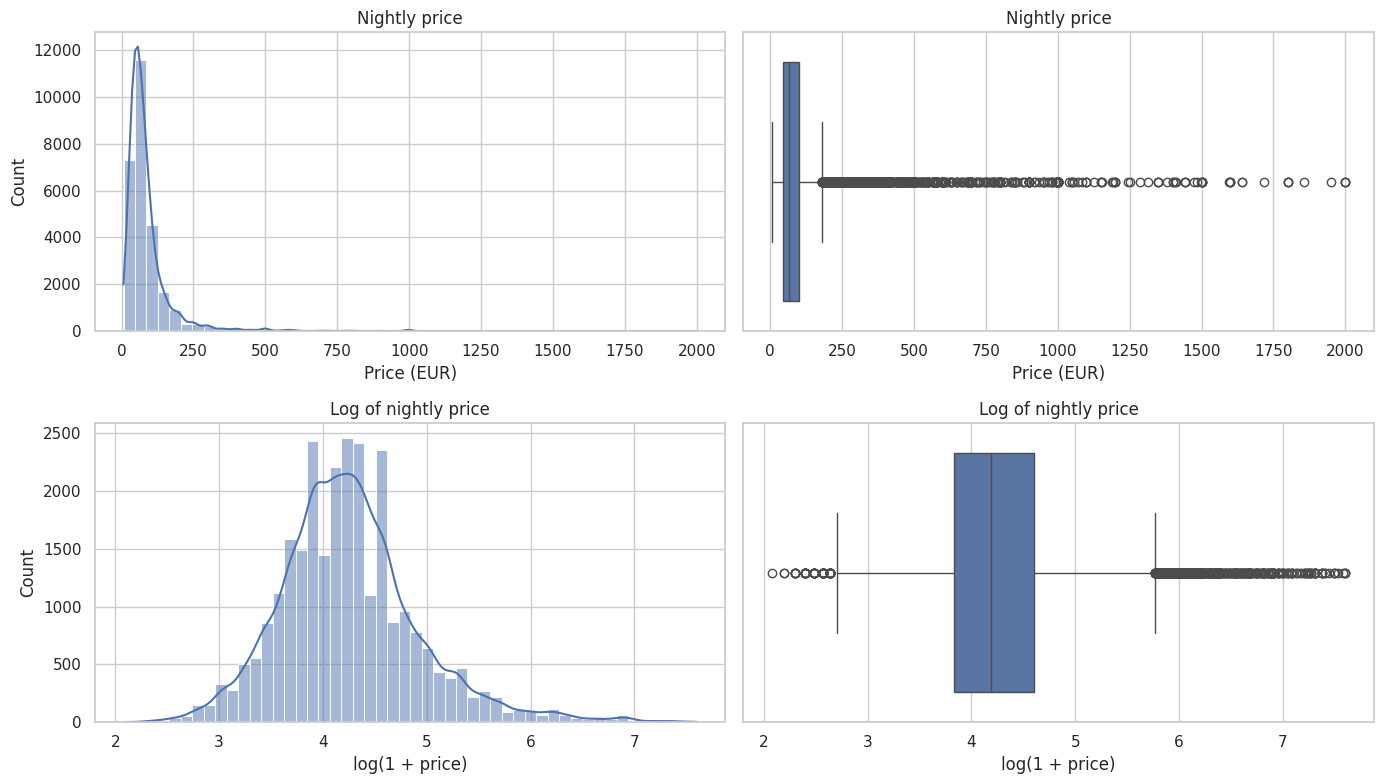

skew price: 6.67 | skew log_price: 0.78


In [19]:
# Price histogram and boxplot, raw and log
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

sns.histplot(df["price"], bins=50, kde=True, ax=axes[0,0])
axes[0,0].set_title("Nightly price"); axes[0,0].set_xlabel("Price (EUR)")
sns.boxplot(x=df["price"], ax=axes[0,1])
axes[0,1].set_title("Nightly price"); axes[0,1].set_xlabel("Price (EUR)")

sns.histplot(df["log_price"], bins=50, kde=True, ax=axes[1,0])
axes[1,0].set_title("Log of nightly price"); axes[1,0].set_xlabel("log(1 + price)")
sns.boxplot(x=df["log_price"], ax=axes[1,1])
axes[1,1].set_title("Log of nightly price"); axes[1,1].set_xlabel("log(1 + price)")

plt.tight_layout();
plt.savefig("fig1_price_log.png", dpi=200, bbox_inches="tight")
plt.show()

print("skew price:", round(df["price"].skew(), 2), "| skew log_price:", round(df["log_price"].skew(), 2))

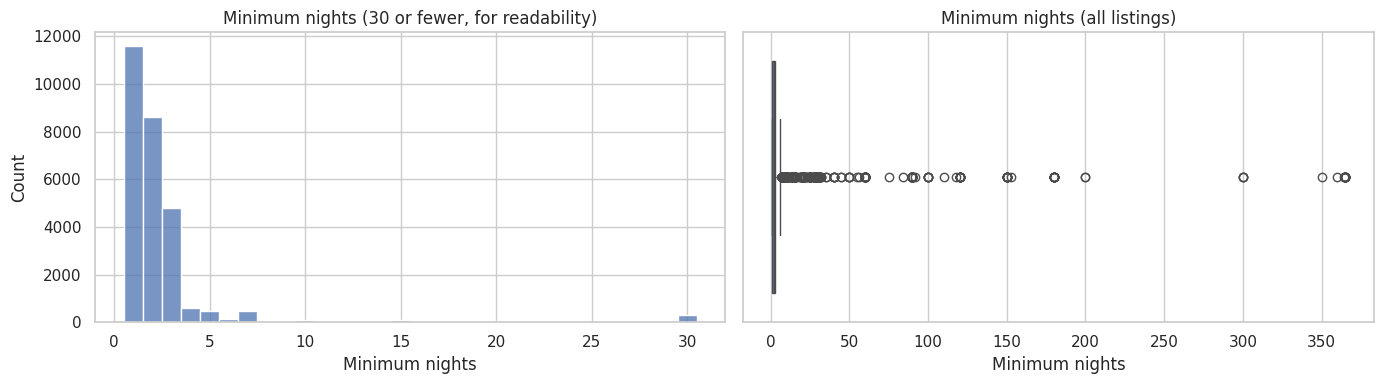

minimum_nights
1     11582
2      8610
3      4782
4       600
5       478
7       463
30      291
6       143
15      102
10       89
Name: count, dtype: int64


In [20]:
# Histogram, cut at 30 for readability and boxplot
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(df.loc[df["minimum_nights"] <= 30, "minimum_nights"], discrete=True, ax=axes[0])
axes[0].set_title("Minimum nights (30 or fewer, for readability)")
axes[0].set_xlabel("Minimum nights")

sns.boxplot(x=df["minimum_nights"], ax=axes[1])
axes[1].set_title("Minimum nights (all listings)")
axes[1].set_xlabel("Minimum nights")

plt.tight_layout(); plt.show()
print(df["minimum_nights"].value_counts().head(10))

20861 scored listings of 27575


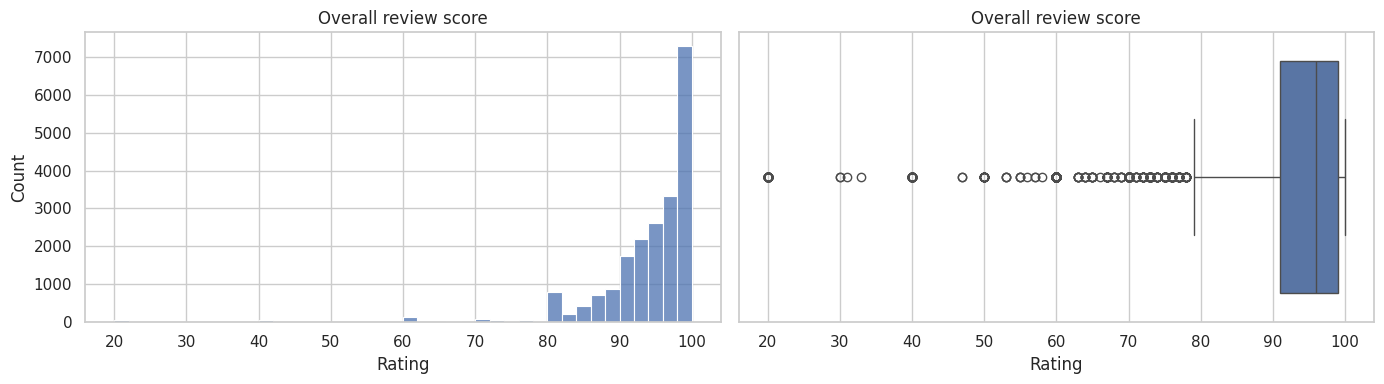

In [21]:
# Review-score histogram and boxplot
scores = df["review_scores_rating"].dropna()
print(len(scores), "scored listings of", len(df))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(scores, binwidth=2, ax=axes[0])
axes[0].set_title("Overall review score"); axes[0].set_xlabel("Rating")
sns.boxplot(x=scores, ax=axes[1])
axes[1].set_title("Overall review score"); axes[1].set_xlabel("Rating")
plt.tight_layout(); plt.show()

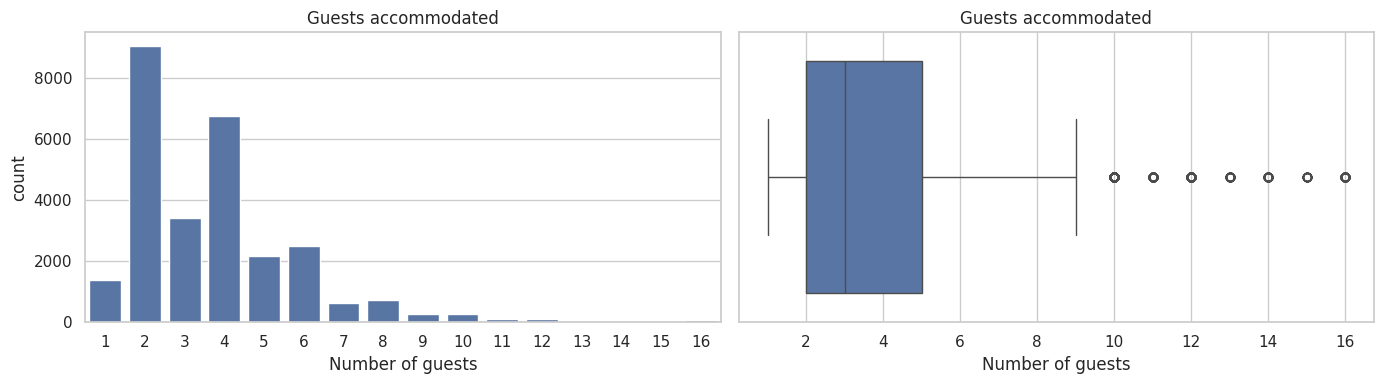

In [22]:
# Bar chart and boxplot
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.countplot(x=df["accommodates"].astype(int), ax=axes[0])
axes[0].set_title("Guests accommodated"); axes[0].set_xlabel("Number of guests")
sns.boxplot(x=df["accommodates"], ax=axes[1])
axes[1].set_title("Guests accommodated"); axes[1].set_xlabel("Number of guests")
plt.tight_layout(); plt.show()

In [23]:
# CATEGORICAL FEATURES
# Count and percentage table for six variables
categorical = ["room_type","property_type","neighbourhood",
               "host_is_superhost","instant_bookable","host_identity_verified"]

for c in categorical:
    counts = df[c].value_counts()
    table = pd.DataFrame({"count": counts, "percent": (counts / len(df) * 100).round(1)})
    print(c, "| levels used:", (counts > 0).sum())
    print(table.head(10), "\n")

room_type | levels used: 4
              count  percent
room_type                   
Entire place  17212     62.4
Private room   8894     32.3
Hotel room     1269      4.6
Shared room     200      0.7 

property_type | levels used: 77
                                    count  percent
property_type                                     
Entire apartment                    14415     52.3
Private room in apartment            4427     16.1
Private room in bed and breakfast    2012      7.3
Entire condominium                   1033      3.7
Private room in condominium           806      2.9
Room in bed and breakfast             632      2.3
Entire house                          590      2.1
Entire loft                           583      2.1
Room in boutique hotel                578      2.1
Private room in serviced apartment    350      1.3 

neighbourhood | levels used: 15
                            count  percent
neighbourhood                             
I Centro Storico            14824

In [24]:
# Keeps the 8 most common property types, groups the rest as “Other”
top_types = df["property_type"].value_counts().head(8).index
df["property_group"] = (df["property_type"].astype(str)
                        .where(df["property_type"].isin(top_types), "Other"))

print(df["property_group"].value_counts(normalize=True).mul(100).round(1))

property_group
Entire apartment                     52.3
Private room in apartment            16.1
Other                                11.2
Private room in bed and breakfast     7.3
Entire condominium                    3.7
Private room in condominium           2.9
Room in bed and breakfast             2.3
Entire house                          2.1
Entire loft                           2.1
Name: proportion, dtype: float64


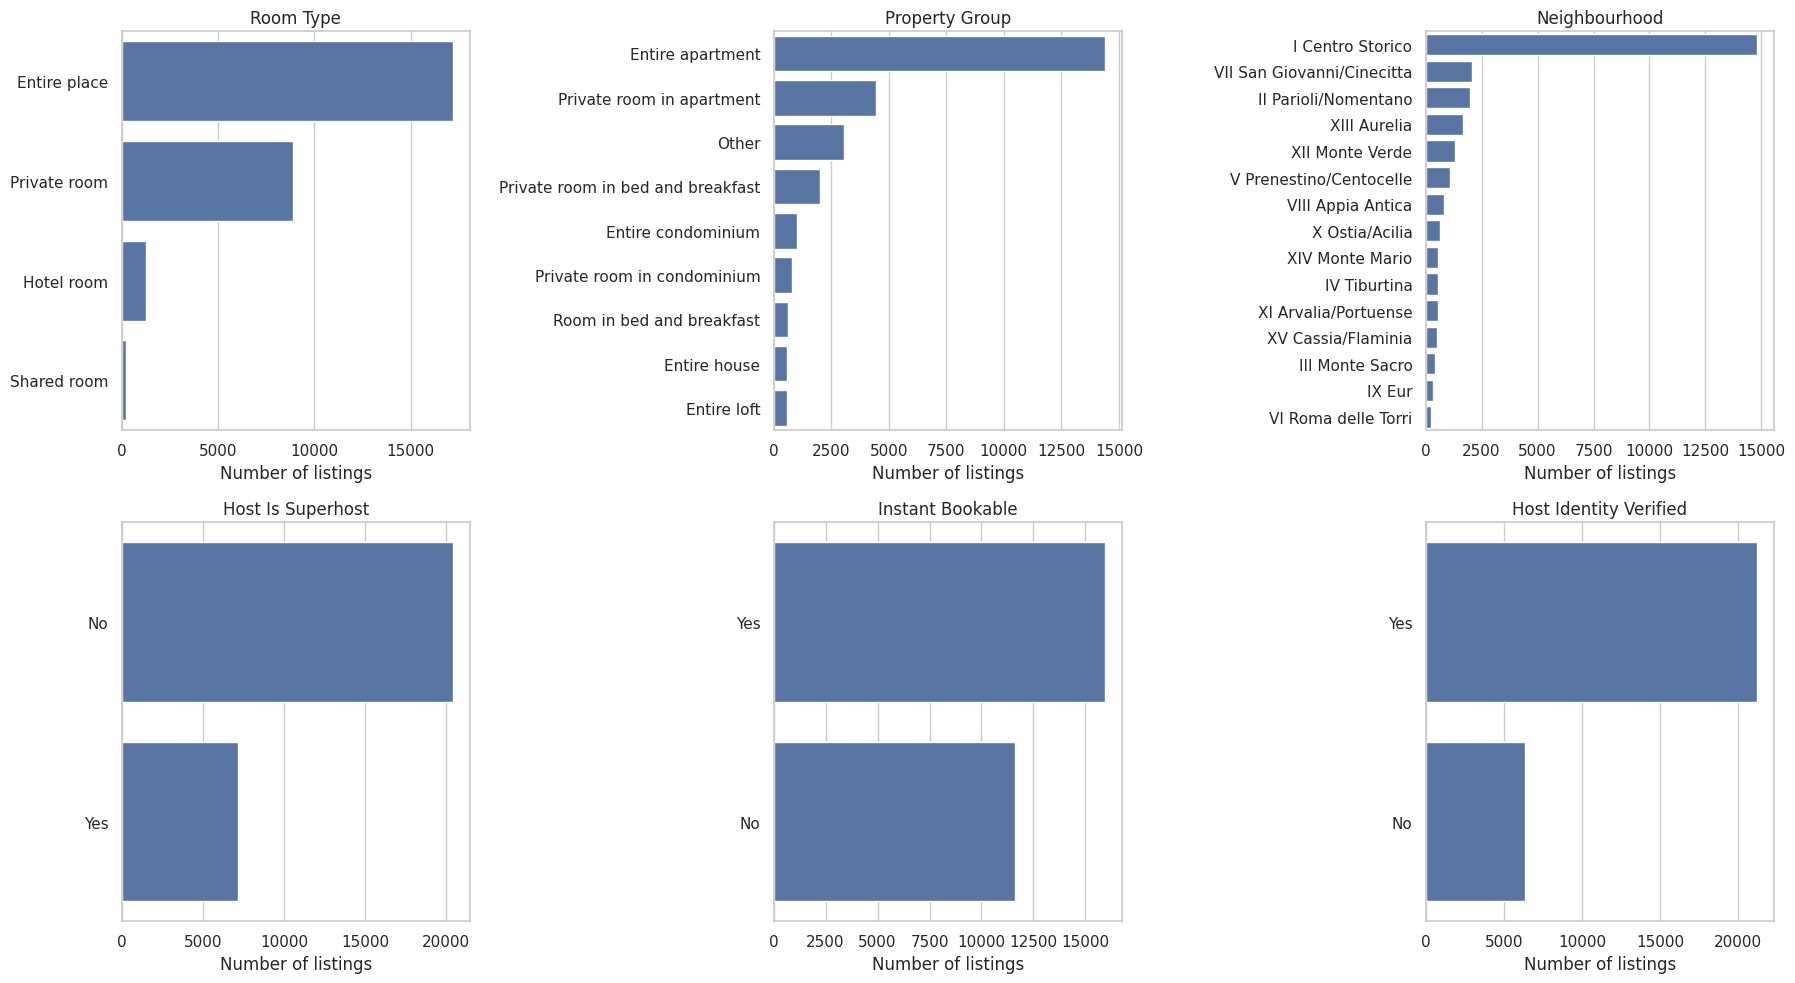

In [25]:
# Bar charts for six variables
plot_cols = ["room_type","property_group","neighbourhood",
             "host_is_superhost","instant_bookable","host_identity_verified"]
binary_cols = ["host_is_superhost","instant_bookable","host_identity_verified"]
yes_no = {"t": "Yes", "f": "No"}

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, c in zip(axes.ravel(), plot_cols):
    labels = df[c].astype(str)
    if c in binary_cols:
        labels = labels.map(yes_no)
    order = labels.value_counts().index
    sns.countplot(data=df.assign(**{c: labels}), y=c, order=order, ax=ax)
    ax.set_title(c.replace("_", " ").title())
    ax.set_xlabel("Number of listings"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

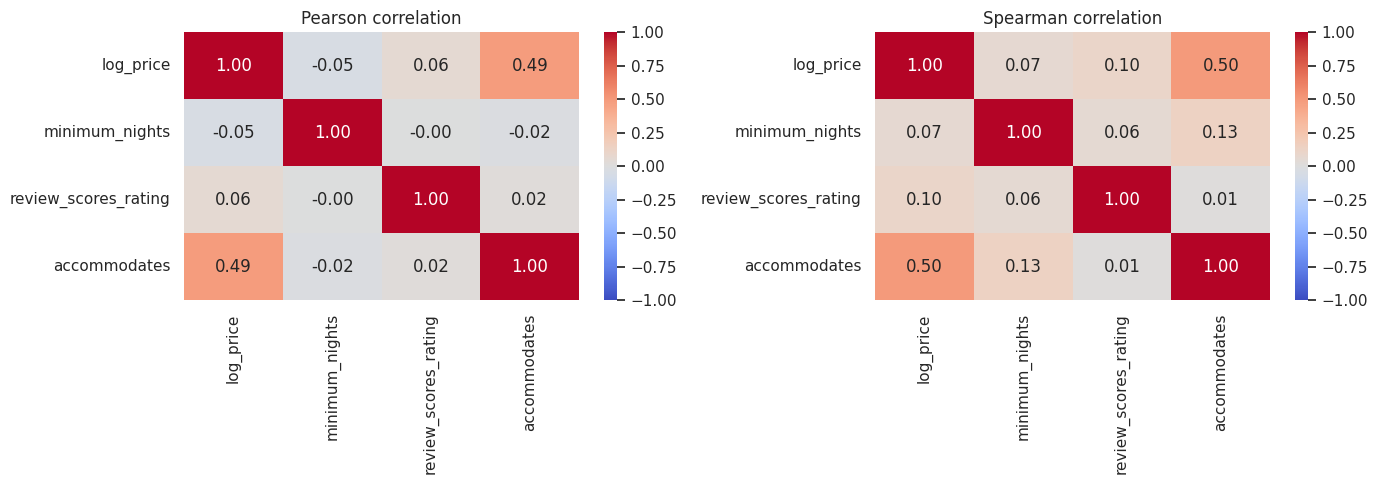

In [26]:
# RELATIONSHIPS BETWEEN FEATURES
# Pearson and Spearman correlation heatmaps
num = ["log_price","minimum_nights","review_scores_rating","accommodates"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, method in zip(axes, ["pearson","spearman"]):
    sns.heatmap(df[num].corr(method=method), annot=True, fmt=".2f",
                cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax)
    ax.set_title(method.title() + " correlation")
plt.tight_layout();
plt.savefig("fig2_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

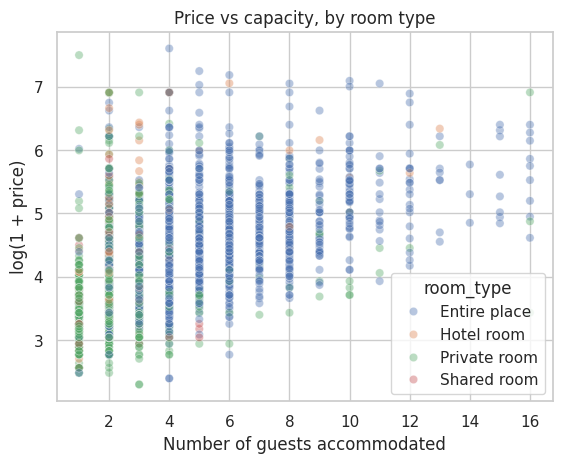

In [27]:
# Scatter of capacity vs log price by room type, on a 5,000 random sample
sample = df.sample(min(5000, len(df)), random_state=42)   # plots only
sns.scatterplot(data=sample, x="accommodates", y="log_price", hue="room_type", alpha=0.4)
plt.title("Price vs capacity, by room type")
plt.xlabel("Number of guests accommodated"); plt.ylabel("log(1 + price)")
plt.show()

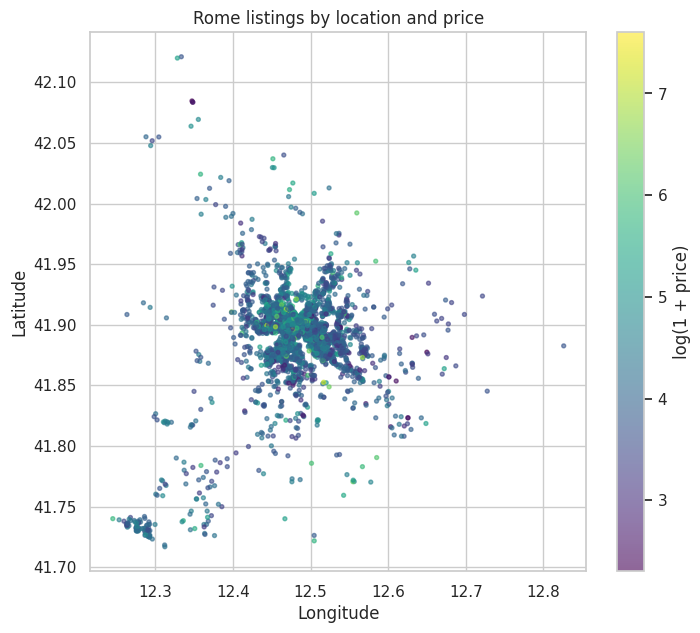

In [28]:
# Map of listings coloured by price
plt.figure(figsize=(8, 7))
sc = plt.scatter(sample["longitude"], sample["latitude"],
                 c=sample["log_price"], cmap="viridis", s=8, alpha=0.6)
plt.colorbar(sc, label="log(1 + price)")
plt.title("Rome listings by location and price")
plt.xlabel("Longitude"); plt.ylabel("Latitude")
plt.show()

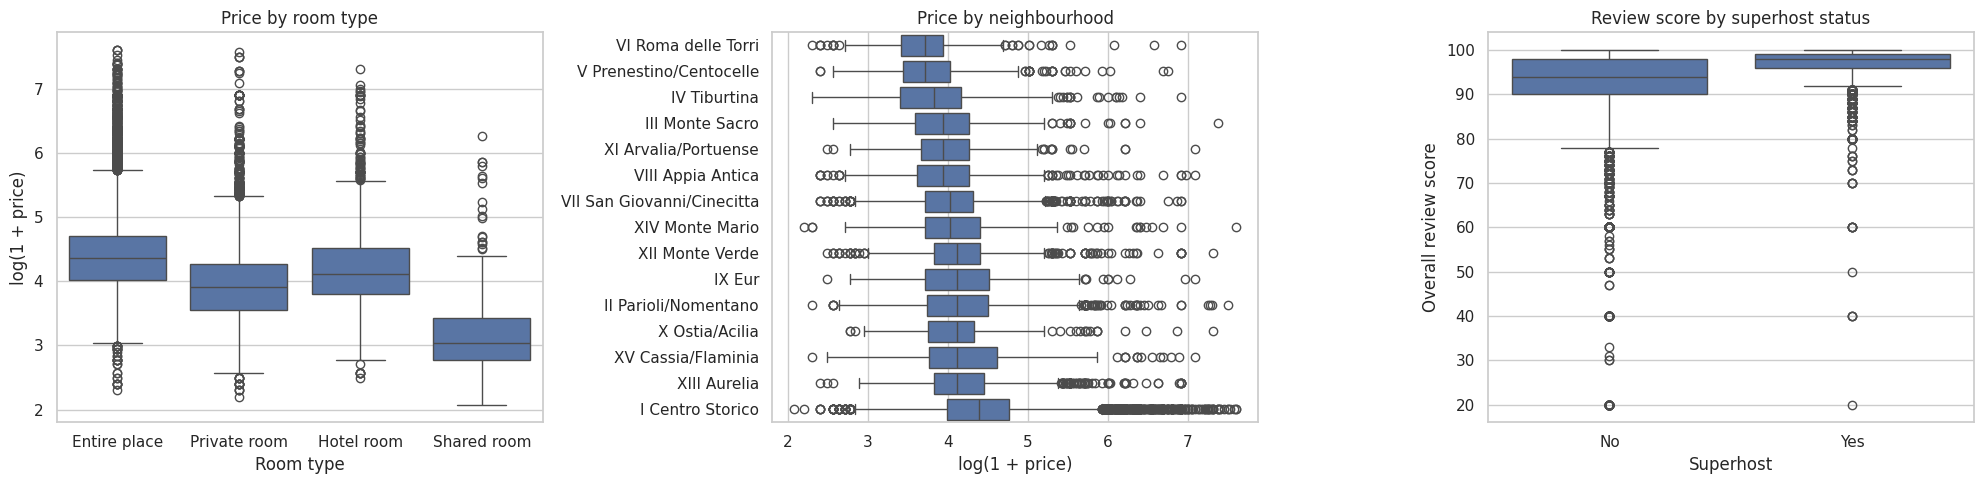

              count   mean  median    std
room_type                                
Entire place  17212  106.6    77.0  119.2
Hotel room     1269   94.6    60.0  127.3
Private room   8894   64.6    49.0   84.4
Shared room     200   38.7    20.0   64.5
KruskalResult(statistic=np.float64(4297.836854113349), pvalue=np.float64(0.0))


In [29]:
# Boxplots showing room type, neighbourhood, superhost vs rating, group table
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

sns.boxplot(data=df.assign(room_type=df["room_type"].astype(str)),
            x="room_type", y="log_price", ax=axes[0])
axes[0].set_title("Price by room type")
axes[0].set_xlabel("Room type"); axes[0].set_ylabel("log(1 + price)")

order = df.groupby("neighbourhood", observed=True)["log_price"].median().sort_values().index.astype(str)
sns.boxplot(data=df.assign(neighbourhood=df["neighbourhood"].astype(str)),
            y="neighbourhood", x="log_price", order=order, ax=axes[1])
axes[1].set_title("Price by neighbourhood")
axes[1].set_xlabel("log(1 + price)"); axes[1].set_ylabel("")

sns.boxplot(data=df.assign(host_is_superhost=df["host_is_superhost"].astype(str).map({"t": "Yes", "f": "No"})),
            x="host_is_superhost", y="review_scores_rating", order=["No", "Yes"], ax=axes[2])
axes[2].set_title("Review score by superhost status")
axes[2].set_xlabel("Superhost"); axes[2].set_ylabel("Overall review score")

plt.tight_layout();
fig.canvas.draw()
for i, name in [(0, "fig3_room_type.png"), (2, "fig4_superhost.png")]:
    bbox = axes[i].get_tightbbox(fig.canvas.get_renderer()).transformed(fig.dpi_scale_trans.inverted())
    fig.savefig(name, dpi=200, bbox_inches=bbox.expanded(1.05, 1.05))
plt.show()

print(df.groupby("room_type", observed=True)["price"].agg(["count","mean","median","std"]).round(1))

groups = [g["price"].values for _, g in df.groupby("room_type", observed=True) if len(g) > 0]
print(stats.kruskal(*groups))

In [30]:
# Median price by neighbourhood, rating by superhost, Mann-Whitney test
print(df.groupby("neighbourhood", observed=True)["price"]
        .agg(["count","median"]).sort_values("median", ascending=False).round(1), "\n")
print(df.groupby("host_is_superhost", observed=True)["review_scores_rating"]
        .agg(["count","mean","median"]).round(1), "\n")
print(df.groupby("instant_bookable", observed=True)["price"].agg(["count","median"]), "\n")

a = df.loc[df["host_is_superhost"] == "t", "review_scores_rating"].dropna()   # superhosts
b = df.loc[df["host_is_superhost"] == "f", "review_scores_rating"].dropna()   # others
u, p = stats.mannwhitneyu(a, b)
print("Mann-Whitney U:", u, "| p:", p)
print("Probability a superhost scores higher than a non-superhost:", round(u / (len(a) * len(b)), 3))

                            count  median
neighbourhood                            
I Centro Storico            14824    79.0
II Parioli/Nomentano         1983    60.0
IX Eur                        347    60.0
XII Monte Verde              1321    60.0
XIII Aurelia                 1689    60.0
XV Cassia/Flaminia            501    60.0
X Ostia/Acilia                631    60.0
VII San Giovanni/Cinecitta   2078    55.0
XIV Monte Mario               573    55.0
XI Arvalia/Portuense          530    50.0
III Monte Sacro               426    50.0
VIII Appia Antica             802    50.0
IV Tiburtina                  532    45.0
VI Roma delle Torri           251    40.0
V Prenestino/Centocelle      1087    40.0 

                   count  mean  median
host_is_superhost                     
f                  14298  92.0    94.0
t                   6563  96.8    98.0 

                  count  median
instant_bookable               
f                 11610    65.0
t                 15965    68.

In [31]:
# Row-percentage crosstab, chi-square test, Cramér’s V
ct = pd.crosstab(df["room_type"], df["host_is_superhost"])
print((ct.div(ct.sum(axis=1), axis=0) * 100).round(1))

chi2, p, dof, _ = stats.chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
print("chi2:", round(chi2, 1), "| p:", p, "| Cramer's V:", round(cramers_v, 3))

host_is_superhost     f     t
room_type                    
Entire place       69.5  30.5
Hotel room         81.5  18.5
Private room       81.5  18.5
Shared room        90.0  10.0
chi2: 506.7 | p: 1.688614611861753e-109 | Cramer's V: 0.136
